# Customer Churn: Modeling

**Goal:** predict which customers will churn.

**Plan**
1. Load, clean and split the data (stratified **70 / 15 / 15**)
2. Train three models in a `for` loop: **Logistic Regression** (baseline), **Random Forest**, **XGBoost**
3. Compare them on the **validation** set using **Precision** and **Recall** (plus F1 and PR-AUC)
4. Pick the best model and evaluate it **once** on the **test** set
5. Save the final model

## 1. Imports and settings

In [ ]:
import sys
import os
from pathlib import Path
import seaborn as sns

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sys.path.append(str(Path.cwd()))
sys.path.append(str(Path.cwd().parent))

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.preprocess import (
    DATA_PATH,
    TARGET,
    add_features,
    build_preprocessor,
    clean_data,
    split_data,
)

SEED = 42
MODELS_PATH = Path("models")
MODELS_PATH.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
FIGURES_DIR = ROOT / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## 2. Load data and split

Steps:
- **Clean** the data (strip spaces, merge duplicate labels, drop exact duplicates)
- **Engineer features** (stateless, so no leakage)
- **Split** 70 / 15 / 15 with stratification so the churn rate stays the same in every part

Duplicates are removed *before* splitting so the same row can't appear in both train and test.

In [2]:
raw = pd.read_csv(DATA_PATH)
df = add_features(clean_data(raw))

# Make sure the target is numeric 0/1
if df[TARGET].dtype == object or str(df[TARGET].dtype) == "string":
    df[TARGET] = df[TARGET].str.strip().str.lower().map({"yes": 1, "no": 0, "1": 1, "0": 0})
df = df.dropna(subset=[TARGET])
df[TARGET] = df[TARGET].astype(int)

print("raw:", raw.shape, "| clean:", df.shape)
df.head()

raw: (3941, 11) | clean: (3269, 15)


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,cashback_per_month,days_since_order_per_month,complain_and_unhappy,tenure_band
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0,8.957500,0.437500,0,13-24m
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0,16.161250,0.875000,0,7-12m
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0,6.019286,0.250000,0,25m+
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0,10.965238,NaN,0,13-24m
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0,10.392581,0.258065,0,25m+


In [3]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df, seed=SEED)

summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "share": [len(y_train) / len(df), len(y_val) / len(df), len(y_test) / len(df)],
    "churn_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "val", "test"])
summary.round(4)

,rows,share,churn_rate
train,2288,0.6999,0.1630
val,490,0.1499,0.1633
test,491,0.1502,0.1629


**Check:** the shares should be about 0.70 / 0.15 / 0.15 and the churn rate should be almost identical in all three parts.
If Churn is the minority class (usually true), plain accuracy is misleading, which is why we focus on **Precision** and **Recall**.

## 3. Define the models

| Model | Scaling | Imbalance handling |
|---|---|---|
| Logistic Regression (baseline) | Yes (linear model) | `class_weight="balanced"` |
| Random Forest | No (trees) | `class_weight="balanced"` |
| XGBoost | No (trees) | `scale_pos_weight = negatives / positives` |

Each model is wrapped in a `Pipeline` together with its own preprocessor, which is **fitted on train only**.

In [4]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "LogisticRegression": (
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        True,   # needs scaling
    ),
    "RandomForest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
        False,
    ),
    "XGBoost": (
        XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=5,
            subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=neg / pos, eval_metric="logloss",
            random_state=SEED, n_jobs=-1,
        ),
        False,
    ),
}
print("scale_pos_weight for XGBoost:", round(neg / pos, 2))

scale_pos_weight for XGBoost: 5.13


## 4. Train and evaluate in a loop

For each model we fit on **train** and score on **validation**:
- **Precision**: of the customers we flag as churners, how many really churn
- **Recall**: of the customers who really churn, how many we catch
- **F1**: harmonic mean of Precision and Recall (one number that balances both)
- **PR-AUC**: threshold-independent quality of the probabilities

In [ ]:
def evaluate(pipe, X, y, threshold=0.5):
    """Return Precision, Recall, F1 and PR-AUC for a fitted pipeline."""
    proba = pipe.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "pr_auc": average_precision_score(y, proba),
    }


results, fitted = [], {}

for name, (model, scale) in models.items():
    pipe = Pipeline([
        ("pre", build_preprocessor(scale=scale)),
        ("model", model),
    ])
    pipe.fit(X_train, y_train)  # preprocessing is fitted on train only
    fitted[name] = pipe

    metrics = evaluate(pipe, X_val, y_val)
    results.append({"model": name, **metrics})
    print(f"{name:20s} " + " | ".join(f"{k}={v:.3f}" for k, v in metrics.items()))

LogisticRegression   precision=0.462 | recall=0.900 | f1=0.610 | pr_auc=0.682


RandomForest         precision=0.757 | recall=0.662 | f1=0.707 | pr_auc=0.788


XGBoost              precision=0.670 | recall=0.863 | f1=0.754 | pr_auc=0.832


## 5. Compare the models (validation set)

The table is sorted by **F1**. If missing a churner is more costly for the business than a false alarm, sort by **Recall** instead.

In [6]:
results_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
results_df.round(4)

,model,precision,recall,f1,pr_auc
0,XGBoost,0.6699,0.8625,0.7541,0.8324
1,RandomForest,0.7571,0.6625,0.7067,0.7875
2,LogisticRegression,0.4615,0.9000,0.6102,0.6815


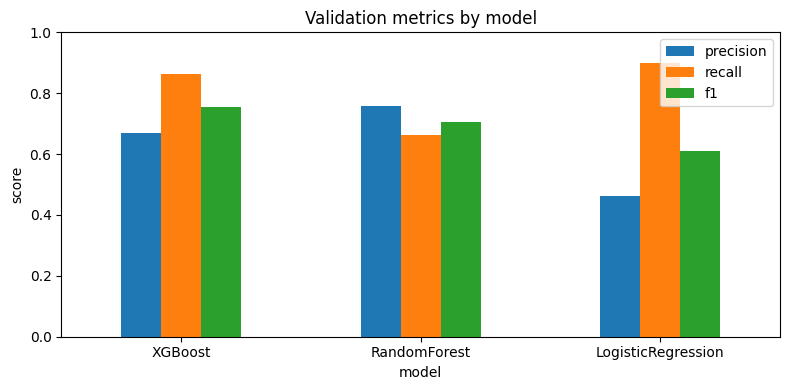

In [7]:
ax = results_df.set_index("model")[["precision", "recall", "f1"]].plot(
    kind="bar", figsize=(8, 4), rot=0, ylim=(0, 1)
)
ax.set_title("Validation metrics by model")
ax.set_ylabel("score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_model_comparison_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

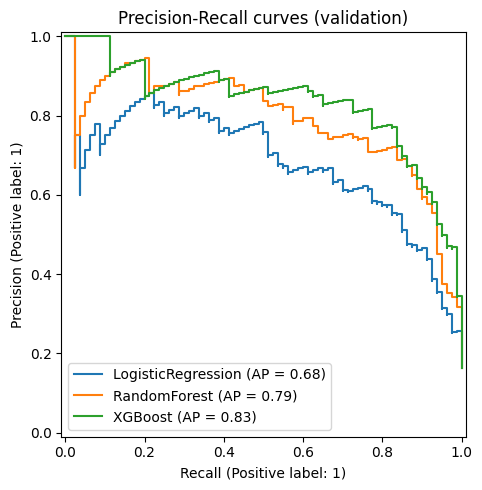

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in fitted.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_val, y_val, name=name, ax=ax)
ax.set_title("Precision-Recall curves (validation)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_precision_recall_curves.png", dpi=300, bbox_inches="tight")
plt.show()

**How to read this:** a curve that stays higher and further to the right means the model keeps good Precision while catching more churners.

## 6. Select the best model

Best model: XGBoost


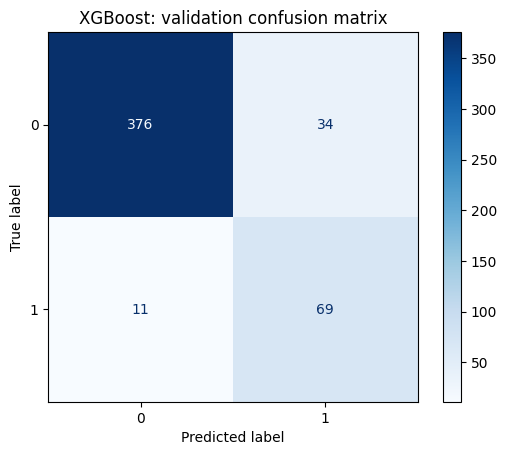

In [9]:
best_name = results_df.loc[0, "model"]
best_pipe = fitted[best_name]
print("Best model:", best_name)

ConfusionMatrixDisplay.from_estimator(best_pipe, X_val, y_val, cmap="Blues")
plt.title(f"{best_name}: validation confusion matrix")
plt.savefig(FIGURES_DIR / "12_validation_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Final evaluation on the test set

The test set is used **once**, only for the chosen model. We don't tune anything based on these numbers.

              precision    recall  f1-score   support

           0      0.960     0.934     0.947       411
           1      0.703     0.800     0.749        80

    accuracy                          0.912       491
   macro avg      0.832     0.867     0.848       491
weighted avg      0.918     0.912     0.915       491



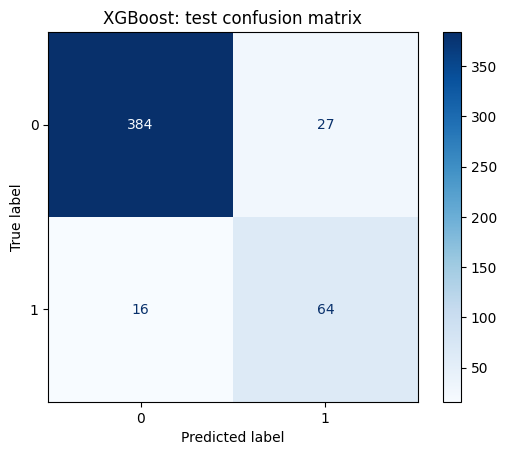

In [10]:
test_pred = best_pipe.predict(X_test)
print(classification_report(y_test, test_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, cmap="Blues")
plt.title(f"{best_name}: test confusion matrix")
plt.savefig(FIGURES_DIR / "13_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Feature Importance

C:\Users\dxt\AppData\Local\Temp\ipykernel_4956\1179535973.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako', ax=ax)


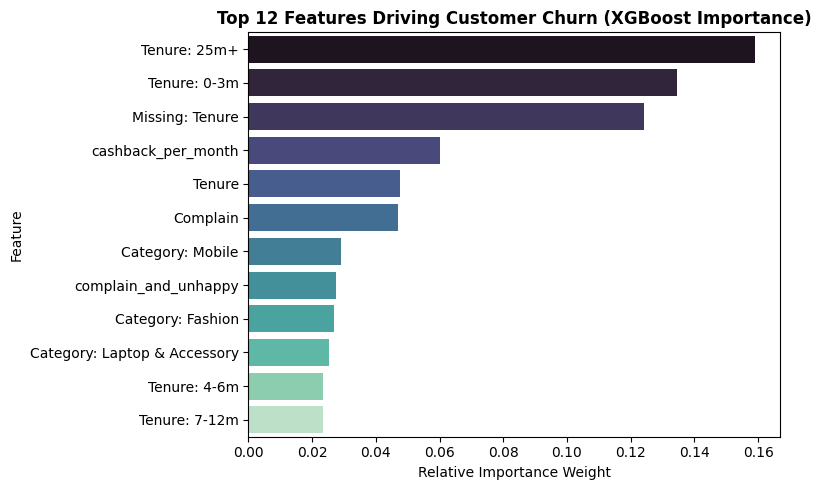

In [11]:
import seaborn as sns
pre = best_pipe.named_steps['pre']
xgb_clf = best_pipe.named_steps['model']
raw_names = pre.get_feature_names_out()

clean_names = [
    n.replace('num__', '')
    .replace('cat__', '')
    .replace('PreferedOrderCat_', 'Category: ')
    .replace('MaritalStatus_', 'Marital: ')
    .replace('tenure_band_', 'Tenure: ')
    .replace('missingindicator_', 'Missing: ')
    for n in raw_names
]

fi_df = (
    pd.DataFrame({'Feature': clean_names, 'Importance': xgb_clf.feature_importances_})
    .sort_values('Importance', ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako', ax=ax)
ax.set_title('Top 12 Features Driving Customer Churn (XGBoost Importance)', fontweight='bold')
ax.set_xlabel('Relative Importance Weight')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '14_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Next Step: Building `src/train.py`

**XGBoost** was the champion model, achieving **91.2% accuracy**, **80.0% recall**, and **0.832 PR-AUC** on the held-out test set.

The next step is to turn this experiment into a reproducible training script, `src/train.py`, that:

1. Loads the raw data and applies the existing `src/preprocess.py` (cleaning, feature engineering, stratified train/test split).
2. Builds the full pipeline `Pipeline([('pre', preprocessor), ('model', xgb_model)])` with the hyperparameters selected in this notebook.
3. Trains the pipeline on the training set and evaluates it on the test set (recall, precision, ROC-AUC, PR-AUC).
4. Saves the fitted pipeline to `models/best_model.pkl`, ready to be used by `predict.py`, the API, and the dashboard.